# MLOps project: heart disease prediction with MLflow

**Dataset:** [Heart Failure Prediction](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction) (Kaggle, fedesoriano), 918 patients, 11 clinical features, binary target `HeartDisease`.

This notebook covers parts 1 to 3 of the assignment. Parts 4 and 5 (FastAPI + form, Docker, Azure Container Instances) live in `app/`, `Dockerfile` and `deploy/`; see `README.md`.

| Step | What happens | MLOps concept |
|---|---|---|
| 0 | Setup, paths, MLflow tracking URI | Reproducible environment |
| 1 | Load and explore data | Data understanding |
| 2 | Preprocessing **inside** an sklearn `Pipeline` | Avoid training/serving skew |
| 3 | Train several models, each in an MLflow run | Experiment tracking (params, metrics, artifacts, model, dataset) |
| 4 | Compare runs and pick the best | Model selection from tracked metrics |
| 5 | Register the best model, set alias `champion` | Model Registry and versioning |
| 6 | Load from the registry and predict | Decoupling training from consumption |
| 7 | Serve with `mlflow models serve` and call `/invocations` | Local model serving |
| 8 | Export the champion into `model/` for the Docker image | Packaging for deployment |

## Step 0: setup

Install the dependencies once from the project root: `pip install -r requirements.txt`.
Run this notebook from the `notebooks/` folder. All MLflow data goes to `mlflow.db` (metadata) and `mlruns/` (artifacts) at the project root, so the MLflow UI and CLI can find them later.

In [3]:
import json
import shutil
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import requests
import sklearn
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "heart.csv"
MODEL_EXPORT_DIR = PROJECT_ROOT / "model"

TRACKING_URI = f"sqlite:///{(PROJECT_ROOT / 'mlflow.db').as_posix()}"
ARTIFACT_ROOT = (PROJECT_ROOT / "mlruns").as_uri()
EXPERIMENT_NAME = "heart-disease-classification"
MODEL_NAME = "heart-disease-classifier"
RANDOM_STATE = 42

print("Project root :", PROJECT_ROOT)
print("Python       :", sys.version.split()[0])
print("MLflow       :", mlflow.__version__, "| scikit-learn:", sklearn.__version__)

Project root : c:\Users\Amine\Documents\Master 2026-2027\MLOps\TP6\mlops-heart-disease
Python       : 3.11.16
MLflow       : 3.17.2 | scikit-learn: 1.9.1


## Step 1: load and explore the data

Two ways to get `heart.csv`:

1. **Manual:** download it from the Kaggle page and put it in `data/heart.csv`.
2. **kagglehub:** the cell below tries it automatically if the file is missing (`pip install kagglehub`; if Kaggle asks for credentials, put your `kaggle.json` in `~/.kaggle/`).

In [5]:
def load_data(path: Path) -> pd.DataFrame:
    if not path.exists():
        import kagglehub  # only needed if the CSV is not there yet
        downloaded = Path(kagglehub.dataset_download("fedesoriano/heart-failure-prediction"))
        path.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(downloaded / "heart.csv", path)
    return pd.read_csv(path)

df = load_data(DATA_PATH)
print(df.shape)
df.head()

100%|██████████| 8.56k/8.56k [00:01<00:00, 6.82kB/s]

Extracting files...
(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [6]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


HeartDisease
1    0.553377
0    0.446623
Name: share, dtype: float64


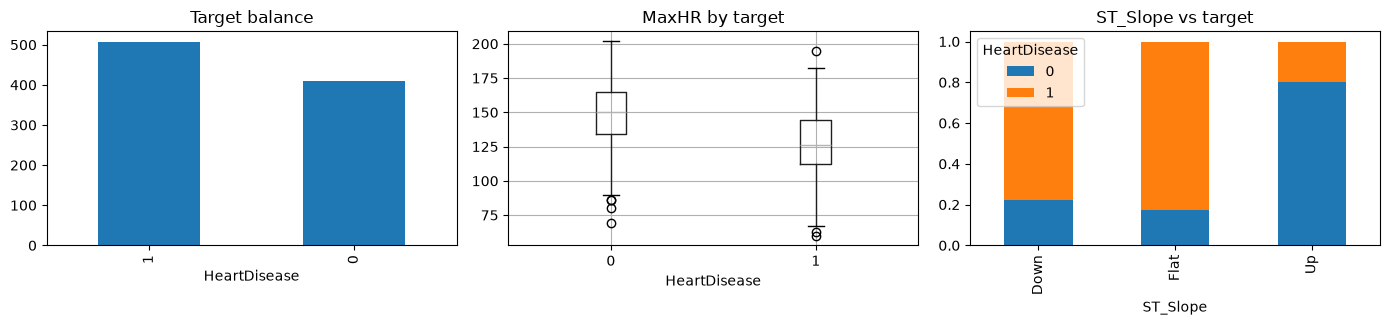

In [7]:
TARGET = "HeartDisease"
print(df[TARGET].value_counts(normalize=True).rename("share"))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
df[TARGET].value_counts().plot.bar(ax=axes[0], title="Target balance")
df.boxplot(column="MaxHR", by=TARGET, ax=axes[1]); axes[1].set_title("MaxHR by target")
pd.crosstab(df["ST_Slope"], df[TARGET], normalize="index").plot.bar(stacked=True, ax=axes[2], title="ST_Slope vs target")
plt.suptitle(""); plt.tight_layout(); plt.show()

### Data quality check

This dataset has a known issue: some rows have `Cholesterol = 0` and `RestingBP = 0`, which are physiologically impossible. They are really **missing values**. We will treat 0 as missing *inside the pipeline* (next step), so the API gets the same treatment automatically.

In [8]:
print("Duplicated rows      :", df.duplicated().sum())
print("Null values          :", int(df.isna().sum().sum()))
print("Cholesterol == 0     :", (df["Cholesterol"] == 0).sum())
print("RestingBP == 0       :", (df["RestingBP"] == 0).sum())

Duplicated rows      : 0
Null values          : 0
Cholesterol == 0     : 172
RestingBP == 0       : 1


## Step 2: preprocessing

**Key MLOps idea:** every transformation (imputation, scaling, encoding) goes inside one `sklearn.Pipeline` together with the model. The logged model then takes **raw** data, exactly as a user types it in the form, and there is no risk that the API preprocesses differently from training (*training/serving skew*).

- `Cholesterol`, `RestingBP`: 0 → median, then scaled
- other numeric features: median imputation, then scaled
- categorical features: most-frequent imputation, then one-hot encoding (`handle_unknown="ignore"` so an unseen category doesn't crash the API)

In [9]:
ZERO_AS_MISSING = ["Cholesterol", "RestingBP"]
NUMERIC = ["Age", "FastingBS", "MaxHR", "Oldpeak"]
CATEGORICAL = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
FEATURES = ZERO_AS_MISSING + NUMERIC + CATEGORICAL

def build_preprocessor() -> ColumnTransformer:
    zero_missing = Pipeline([
        ("impute", SimpleImputer(missing_values=0, strategy="median")),
        ("scale", StandardScaler()),
    ])
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("zero_missing", zero_missing, ZERO_AS_MISSING),
        ("num", numeric, NUMERIC),
        ("cat", categorical, CATEGORICAL),
    ])

# Cast integer columns to float so the MLflow signature accepts decimals and missing values later
X = df[FEATURES].astype({c: "float64" for c in ZERO_AS_MISSING + NUMERIC})
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(734, 11) (184, 11)


## Step 3: experiment tracking with MLflow

Each model trained = one MLflow **run** inside the experiment `heart-disease-classification`. For each run we log:

- **parameters**: model type and hyperparameters, test size, random seed
- **metrics**: 5-fold cross-validated ROC AUC on train (mean and std), plus accuracy, precision, recall, F1 and ROC AUC on the test set
- **artifacts**: confusion matrix (PNG) and classification report (text)
- **dataset**: the training data, so you know which data produced which model
- **model**: the whole pipeline, with a **signature** (expected input schema) and an **input example**

> Tip: `mlflow.sklearn.autolog()` does much of this automatically. Logging manually here is more explicit and easier to explain in a report.

In [10]:
mlflow.set_tracking_uri(TRACKING_URI)
if mlflow.get_experiment_by_name(EXPERIMENT_NAME) is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=ARTIFACT_ROOT)
mlflow.set_experiment(EXPERIMENT_NAME)
print("Tracking URI:", mlflow.get_tracking_uri())

2026/11/06 22:10:18 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/06 22:10:18 INFO mlflow.store.db.utils: Updating database tables


Tracking URI: sqlite:///c:/Users/Amine/Documents/Master 2026-2027/MLOps/TP6/mlops-heart-disease/mlflow.db


**About `skops_trusted_types`:** recent MLflow versions save sklearn models with [skops](https://skops.readthedocs.io/) instead of pickle by default. Pickle can execute arbitrary code when a model file is loaded, which is a real supply-chain risk; skops only rebuilds object types it trusts. Our pipelines contain two types skops does not trust by default: `numpy.dtype` (inside `OneHotEncoder`) and `sklearn.tree._tree.Tree` (inside the tree models). We trained these models ourselves, so we declare exactly those two as trusted, and nothing more. Worth one paragraph in your report under security.

In [11]:
SKOPS_TRUSTED_TYPES = [
    "numpy.dtype",              # stored by OneHotEncoder
    "sklearn.tree._tree.Tree",  # node storage of RandomForest / GradientBoosting
]

def train_and_log(run_name: str, estimator, params: dict) -> dict:
    estimator.set_params(**params)
    pipe = Pipeline([("preprocess", build_preprocessor()), ("model", estimator)])

    with mlflow.start_run(run_name=run_name) as run:
        # Tags and parameters
        mlflow.set_tags({"model_family": type(estimator).__name__, "dataset": "kaggle/heart-failure-prediction"})
        mlflow.log_params({"model_type": type(estimator).__name__, "test_size": 0.2,
                           "random_state": RANDOM_STATE, **params})

        # Dataset lineage
        mlflow.log_input(mlflow.data.from_pandas(X_train.assign(**{TARGET: y_train}),
                                                 source=str(DATA_PATH), targets=TARGET, name="heart-train"),
                         context="training")

        # Cross-validation on the training set
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
        cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")

        # Final fit and evaluation on the held-out test set
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)
        y_proba = pipe.predict_proba(X_test)[:, 1]
        metrics = {
            "cv_roc_auc_mean": cv_auc.mean(), "cv_roc_auc_std": cv_auc.std(),
            "test_accuracy": accuracy_score(y_test, y_pred),
            "test_precision": precision_score(y_test, y_pred),
            "test_recall": recall_score(y_test, y_pred),
            "test_f1": f1_score(y_test, y_pred),
            "test_roc_auc": roc_auc_score(y_test, y_proba),
        }
        mlflow.log_metrics(metrics)

        # Artifacts
        fig, ax = plt.subplots(figsize=(4, 4))
        ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, colorbar=False)
        ax.set_title(run_name)
        mlflow.log_figure(fig, "confusion_matrix.png")
        plt.close(fig)
        mlflow.log_text(classification_report(y_test, y_pred), "classification_report.txt")

        # Model with signature + input example
        signature = infer_signature(X_train, pipe.predict(X_train))
        model_info = mlflow.sklearn.log_model(
            sk_model=pipe, name="model", signature=signature, input_example=X_train.head(3),
            skops_trusted_types=SKOPS_TRUSTED_TYPES)

    print(f"{run_name:<28} test ROC AUC={metrics['test_roc_auc']:.3f}  F1={metrics['test_f1']:.3f}")
    return {"run_id": run.info.run_id, "model_uri": model_info.model_uri, **metrics}

### Train several candidate models

Each call below creates a separate run. Feel free to add models or hyperparameter combinations: that is exactly what experiment tracking is for.

In [12]:
experiments = [
    ("logreg_C1", LogisticRegression(max_iter=1000), {"C": 1.0}),
    ("logreg_C0.1", LogisticRegression(max_iter=1000), {"C": 0.1}),
    ("rf_200_depth6", RandomForestClassifier(random_state=RANDOM_STATE), {"n_estimators": 200, "max_depth": 6}),
    ("rf_400_depthNone", RandomForestClassifier(random_state=RANDOM_STATE), {"n_estimators": 400, "max_depth": None}),
    ("gb_lr0.05", GradientBoostingClassifier(random_state=RANDOM_STATE), {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 3}),
]
results = [train_and_log(name, est, params) for name, est, params in experiments]

c:\Users\Amine\.conda\envs\rl\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
c:\Users\Amine\.conda\envs\rl\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/d

logreg_C1                    test ROC AUC=0.933  F1=0.899


c:\Users\Amine\.conda\envs\rl\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
c:\Users\Amine\.conda\envs\rl\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/d

logreg_C0.1                  test ROC AUC=0.935  F1=0.903


c:\Users\Amine\.conda\envs\rl\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
c:\Users\Amine\.conda\envs\rl\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/d

rf_200_depth6                test ROC AUC=0.931  F1=0.900


c:\Users\Amine\.conda\envs\rl\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
c:\Users\Amine\.conda\envs\rl\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/d

rf_400_depthNone             test ROC AUC=0.931  F1=0.899


c:\Users\Amine\.conda\envs\rl\Lib\site-packages\mlflow\data\dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
c:\Users\Amine\.conda\envs\rl\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/d

gb_lr0.05                    test ROC AUC=0.917  F1=0.887


## Step 4: compare the runs

You can compare them in code (below) or visually in the MLflow UI. From the **project root**, in a terminal:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```

Then open http://127.0.0.1:5000. Take screenshots of the runs table, the comparison view and a run's artifacts for your report.

In [13]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME], order_by=["metrics.test_roc_auc DESC"])
cols = ["tags.mlflow.runName", "params.model_type", "metrics.cv_roc_auc_mean",
        "metrics.test_roc_auc", "metrics.test_f1", "metrics.test_recall"]
runs[cols].round(3)

,tags.mlflow.runName,params.model_type,metrics.cv_roc_auc_mean,metrics.test_roc_auc,metrics.test_f1,metrics.test_recall
0,logreg_C0.1,LogisticRegression,0.921,0.935,0.903,0.912
1,logreg_C1,LogisticRegression,0.922,0.933,0.899,0.912
2,rf_200_depth6,RandomForestClassifier,0.931,0.931,0.900,0.922
3,rf_400_depthNone,RandomForestClassifier,0.926,0.931,0.899,0.912
4,gb_lr0.05,GradientBoostingClassifier,0.919,0.917,0.887,0.882


In [14]:
# Selection rule: best test ROC AUC among the runs of this session.
# (Recall also matters in a medical context: a missed sick patient is costly. Discuss this choice in your report.)
best = max(results, key=lambda r: r["test_roc_auc"])
print("Best run:", best["run_id"], "| test ROC AUC:", round(best["test_roc_auc"], 3))

Best run: c91acf4afa7247af896235a7c99f4059 | test ROC AUC: 0.935


## Step 5: register the best model

The **Model Registry** gives the model a name and versions. Each registration creates version 1, 2, 3… We point the alias **`champion`** at the version to serve. The API and the CLI ask for `models:/heart-disease-classifier@champion`, so promoting a new model is just moving the alias, with no code change.

In [15]:
client = MlflowClient()
mv = mlflow.register_model(model_uri=best["model_uri"], name=MODEL_NAME)
client.set_registered_model_alias(MODEL_NAME, "champion", mv.version)
client.update_registered_model(MODEL_NAME, description="Predicts heart disease (0/1) from 11 clinical features. Full sklearn pipeline: raw input in, prediction out.")
client.update_model_version(MODEL_NAME, mv.version, description=f"From run {best['run_id']}, test ROC AUC={best['test_roc_auc']:.3f}")
print(f"Registered {MODEL_NAME} version {mv.version} with alias @champion")

Registered heart-disease-classifier version 1 with alias @champion


Successfully registered model 'heart-disease-classifier'.
Created version '1' of model 'heart-disease-classifier'.


## Step 6: load the model from the registry and predict

Anyone with access to the tracking server can now use the model without knowing how it was trained.
- `mlflow.pyfunc` is the generic interface (the same one used by `mlflow models serve`): it returns the class.
- `mlflow.sklearn` gives back the original pipeline, so `predict_proba` is available.

In [16]:
CHAMPION_URI = f"models:/{MODEL_NAME}@champion"
pyfunc_model = mlflow.pyfunc.load_model(CHAMPION_URI)
sk_model = mlflow.sklearn.load_model(CHAMPION_URI)

sample = X_test.head(5)
pd.DataFrame({"true": y_test.head(5).values,
              "predicted": pyfunc_model.predict(sample),
              "proba_disease": sk_model.predict_proba(sample)[:, 1].round(3)}, index=sample.index)

,true,predicted,proba_disease
356,1,1,0.927
763,1,0,0.188
817,1,1,0.942
735,1,1,0.558
892,0,0,0.182


## Step 7: serve the model locally with MLflow

MLflow can expose any registered model as a REST endpoint. Normally you run this **in a terminal** from the project root:

```bash
# macOS / Linux
export MLFLOW_TRACKING_URI=sqlite:///mlflow.db
# Windows PowerShell:  $env:MLFLOW_TRACKING_URI="sqlite:///mlflow.db"

mlflow models serve -m "models:/heart-disease-classifier@champion" -p 5001 --env-manager local
```

`--env-manager local` reuses your current Python environment instead of building a new one (faster, and avoids needing pyenv/virtualenv).

The server exposes `GET /ping` (health) and `POST /invocations` (predictions). The cell below starts the same server in the background from the notebook, calls it, then stops it, so the notebook runs end to end. If you started the server yourself in a terminal, set `START_FROM_NOTEBOOK = False`.

In [18]:
START_FROM_NOTEBOOK = True
SERVE_PORT = 5001
SERVE_URL = f"http://127.0.0.1:{SERVE_PORT}"

server = None
if START_FROM_NOTEBOOK:
    import os
    env = {**os.environ, "MLFLOW_TRACKING_URI": TRACKING_URI}
    server = subprocess.Popen(
        [sys.executable, "-m", "mlflow", "models", "serve", "-m", CHAMPION_URI,
         "-p", str(SERVE_PORT), "--env-manager", "local"],
        env=env, cwd=PROJECT_ROOT, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)

for _ in range(60):  # wait up to ~60 s for the server to come up
    try:
        if requests.get(f"{SERVE_URL}/ping", timeout=1).status_code == 200:
            print("MLflow model server is up at", SERVE_URL)
            break
    except requests.exceptions.ConnectionError:
        time.sleep(1)
else:
    print("Server did not respond: start it in a terminal with the command above.")

MLflow model server is up at http://127.0.0.1:5001


In [19]:
# MLflow's scoring protocol: a JSON body with "dataframe_split" (or "dataframe_records")
payload = {"dataframe_split": X_test.head(3).to_dict(orient="split")}
resp = requests.post(f"{SERVE_URL}/invocations", json=payload, timeout=10)
print(resp.status_code, resp.json())

# Same thing with one hand-written patient, as the form will send it
patient = {"Age": 54, "Sex": "M", "ChestPainType": "ASY", "RestingBP": 140, "Cholesterol": 239,
           "FastingBS": 0, "RestingECG": "Normal", "MaxHR": 160, "ExerciseAngina": "N",
           "Oldpeak": 1.2, "ST_Slope": "Flat"}
resp = requests.post(f"{SERVE_URL}/invocations", json={"dataframe_records": [patient]}, timeout=10)
print(resp.status_code, resp.json())

200 {'predictions': [1, 0, 1]}
200 {'predictions': [1]}


Equivalent `curl` call (useful for the report):

```bash
curl -X POST http://127.0.0.1:5001/invocations -H "Content-Type: application/json" \
  -d '{"dataframe_records": [{"Age": 54, "Sex": "M", "ChestPainType": "ASY", "RestingBP": 140, "Cholesterol": 239, "FastingBS": 0, "RestingECG": "Normal", "MaxHR": 160, "ExerciseAngina": "N", "Oldpeak": 1.2, "ST_Slope": "Flat"}]}'
```

In [20]:
if server is not None:
    server.terminate()
    server.wait(timeout=10)
    print("MLflow model server stopped.")

MLflow model server stopped.


## Step 8: export the champion model for the API and Docker

Azure Container Instances cannot reach the MLflow database on your laptop, so the champion model is **copied into `model/`** and baked into the Docker image. The folder is a standard MLflow model: `MLmodel` (metadata + signature), `model.pkl`, and `requirements.txt` with the **exact library versions** used in training. The Dockerfile installs from that file, so the container runs the same versions as the notebook.

In [21]:
if MODEL_EXPORT_DIR.exists():
    shutil.rmtree(MODEL_EXPORT_DIR)
MODEL_EXPORT_DIR.mkdir(parents=True)
mlflow.artifacts.download_artifacts(artifact_uri=CHAMPION_URI, dst_path=str(MODEL_EXPORT_DIR))

# Traceability: record which registry version and run this export comes from (served by the API at /info)
(MODEL_EXPORT_DIR / "model_info.json").write_text(json.dumps({
    "model_name": MODEL_NAME, "version": int(mv.version), "alias": "champion",
    "run_id": best["run_id"], "test_roc_auc": round(best["test_roc_auc"], 4),
    "test_f1": round(best["test_f1"], 4), "features": FEATURES,
}, indent=2))

print(sorted(p.name for p in MODEL_EXPORT_DIR.iterdir()))
print((MODEL_EXPORT_DIR / "requirements.txt").read_text())

['MLmodel', 'conda.yaml', 'input_example.json', 'model.skops', 'model_info.json', 'python_env.yaml', 'registered_model_meta', 'requirements.txt', 'serving_input_example.json']
mlflow==3.17.2
numpy==2.3.2
pandas==3.0.6
psutil==7.2.2
scikit-learn==1.9.1
scipy==1.17.1
skops==0.16.0
torch==2.14.1
tqdm==4.70.1


In [22]:
# Sanity check: the exported folder loads on its own, with no tracking server involved
exported = mlflow.sklearn.load_model(str(MODEL_EXPORT_DIR))
print(exported.predict_proba(pd.DataFrame([patient]).astype({c: "float64" for c in ZERO_AS_MISSING + NUMERIC}))[:, 1])

[0.74837407]


## Next steps

The model is trained, tracked, registered, served and exported. Continue with `README.md`:

- **Part 4:** run the FastAPI app (`app/main.py`) and use the form at http://127.0.0.1:8000
- **Part 5:** build the Docker image and deploy it to Azure Container Instances (`deploy/deploy_aci.sh`)

Ideas to go further: log a SHAP or feature-importance plot as an artifact, try `mlflow.sklearn.autolog()`, add an `XGBoost` run, or write a small script that moves `@champion` only if a new run beats the current one.